# Clasificación de la función de cita con un LLM en Ollama (gemma3:12b)

Este notebook evalúa un LLM de Ollama (gemma3:12b) como **modelo de referencia** frente a SciBERT. Al modelo se le pasa **solo**:

- el **contexto** (`left_context + citing_sentence + right_context`),
- el **título** del documento citado (`cited_title`),
- el **resumen** del documento citado (`cited_abstract`).

**No recibe los chunks.** El prompt (definiciones, criterios y reglas de las 9 funciones) es el mismo que usaron los jueces en el notebook de pre-etiquetado, para establecer el mismo marco de comparación.

Usamos el modelo gemma3:12b que es de una familia distinta a la de los jueces (`llama3.1:8b`, `qwen2.5:7b`, `mistral-nemo`).

Los datos se leen de `train.json`, `val.json` y `test.json`:

| Archivo | Uso en este notebook |
|---|---|
| `train.json` | Ejemplos opcionales para el prompt (*few-shot*) y distribución de clases |
| `val.json` | Evaluación intermedia |
| `test.json` | Evaluación final |


## 1. Conexión con los directorios

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Parámetros

In [2]:
import os, re, json, random, time, subprocess, urllib.request, urllib.error
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DRIVE_DIR = "/content/drive/MyDrive/Colab Notebooks/proyecto"
DATA_DIR = f"{DRIVE_DIR}/data"
TRAIN_PATH = f"{DATA_DIR}/train.json"
VAL_PATH = f"{DATA_DIR}/val.json"
TEST_PATH = f"{DATA_DIR}/test.json"

MODEL = "gemma3:12b"
OLLAMA_URL = "http://localhost:11434"
OUTPUT_DIR = f"{DRIVE_DIR}/models/ollama_" + re.sub(r"[^A-Za-z0-9_.-]", "_", MODEL)

TEMPERATURE = 0.0
NUM_CTX = 4096
MAX_TOKENS = 120
MAX_ABSTRACT_CHARS = 2500
TIMEOUT = 180
RETRIES = 3
WORKERS = 2
SEED = 13

FEW_SHOT_PER_CLASS = 0

EVAL_SPLITS = ["val", "test"]
ONLY_REAL = True
LIMIT_PER_CLASS = {"val": 100, "test": None}

LABEL_COL = "selected_function"
ORIGIN_COL = "origin"

try:
    os.makedirs(OUTPUT_DIR, exist_ok=True)
except OSError:
    print("Aviso: no se pudo crear OUTPUT_DIR (¿Drive sin montar?).")
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

## 3. Instalar Ollama


In [3]:
%%bash
apt-get update -qq && apt-get install -y -qq zstd
curl -fsSL https://ollama.com/install.sh | sh

Selecting previously unselected package zstd.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../zstd_1.5.5+dfsg2-2build1.1_amd64.deb ...
Unpacking zstd (1.5.5+dfsg2-2build1.1) ...
Setting up zstd (1.5.5+dfsg2-2build1.1) ...
Processing triggers for man-db (2.12.0-4build2) ...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [4]:
def ollama_ready():
    try:
        urllib.request.urlopen(f"{OLLAMA_URL}/api/tags", timeout=2)
        return True
    except Exception:
        return False

if not ollama_ready():
    env = {**os.environ, "OLLAMA_NUM_PARALLEL": str(WORKERS), "OLLAMA_KEEP_ALIVE": "30m"}
    subprocess.Popen(["ollama", "serve"], stdout=open("ollama.log", "w"), stderr=subprocess.STDOUT, env=env)
    for _ in range(60):
        if ollama_ready():
            break
        time.sleep(1)
print("Servidor de Ollama listo:", ollama_ready())

if ollama_ready():
    print(f"Descargando {MODEL}...")
    subprocess.run(["ollama", "pull", MODEL], check=True)
    print(subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout)

Servidor de Ollama listo: True
Descargando gemma3:12b...
NAME          ID              SIZE      MODIFIED               
gemma3:12b    b92b218582c5    8.2 GB    Less than a second ago    



## 4. Carga de los archivos de datos

In [5]:
REQUIRED = ["left_context", "citing_sentence", "right_context", "cited_title", "cited_abstract", LABEL_COL]

def load_split(path):
    if not os.path.exists(path):
        raise FileNotFoundError(f"No existe {path}. Revisa DATA_DIR y que Drive esté montado.")
    with open(path, encoding="utf-8") as f:
        recs = json.load(f)
    faltan = [c for c in REQUIRED if any(c not in r for r in recs[:1000])]
    if faltan:
        raise KeyError(f"Faltan campos en {os.path.basename(path)}: {faltan}")
    return recs

splits = {"train": load_split(TRAIN_PATH), "val": load_split(VAL_PATH), "test": load_split(TEST_PATH)}
print({k: len(v) for k, v in splits.items()})

dist = pd.DataFrame({k: Counter(r[LABEL_COL] for r in v) for k, v in splits.items()}).fillna(0).astype(int)
dist.loc["TOTAL"] = dist.sum()
display(dist)

if ORIGIN_COL in splits["train"][0]:
    orig = pd.DataFrame({k: Counter(r.get(ORIGIN_COL) for r in v) for k, v in splits.items()}).fillna(0).astype(int)
    print("Origen de los datos por grupo:")
    display(orig)

{'train': 28224, 'val': 6048, 'test': 6048}


,train,val,test
Identification of the Originator,3136,672,672
Evidence,3136,672,672
Gap,3136,672,672
Further Reading,3136,672,672
Basis,3136,672,672
Improvement/Modification,3136,672,672
Background,3136,672,672
Comparison,3136,672,672
Application,3136,672,672
TOTAL,28224,6048,6048


Origen de los datos por grupo:


,train,val,test
real,7842,1682,0
synthetic,20382,4366,2329
doc_manual,0,0,3249
manual,0,0,470


## 5. Categorías y prompt

Se reutilizan las definiciones, criterios, reglas y el análisis de respuestas del notebook de pre-etiquetado, con el contexto **más título y resumen** del documento citado.

In [6]:
import re

CATEGORIES = [
    ("Background",
     "Citations used to provide context, summarize the general background of a research topic, or trace the history of a field or idea. These citations lay the foundation for understanding the focal study.",
     ["Reviews existing literature to ensure comprehensiveness.",
      "Cites review papers or relevant previous studies to depict the current state of the field.",
      "Highlights important or prevailing findings in the field.",
      "Traces the historical development or presents key ideas in the subject area.",
      "Do NOT use when the present work is said to be built on the cited work (Basis), when the sentence "
      "credits who first introduced an idea (Identification of the Originator), when it sends the reader to "
      "the source for details (Further Reading), or when it stresses what is missing (Gap)."]),
    ("Gap",
     "Citations that help identify research gaps or unexplored areas, justifying the author’s choice of research topic.",
     ["Highlights what has or has not been done in the research area.",
      "Identifies gaps in knowledge or areas for further study.",
      "Justifies the relevance and importance of the current research by contrasting it with existing work.",
      "Do NOT use when the sentence neutrally summarizes prior work (Background), or when it contrasts "
      "methods or results without saying that something is missing (Comparison)."]),
    ("Basis",
     "Citations that provide a foundation for the current research. This can operate at a macro level (broad influence) or a micro level (specific key contributions).",
     ["Serves as the intellectual starting point for the focal research.",
      "The cited work significantly shapes the research idea or hypothesis.",
      "The focal research builds upon, continues, or expands on the cited work.",
      "Do NOT use for general related work (Background); when a concrete method, tool, model or dataset is "
      "used unchanged (Application) or changed (Improvement/Modification); or when the sentence only credits "
      "who first introduced an idea (Identification of the Originator)."]),
    ("Comparison",
     "Citations used to compare the current work with cited studies or to draw comparisons between cited studies.",
     ["Highlights similarities or differences between the current research and cited works.",
      "Compares methodologies, findings, algorithms, data, or theoretical concepts.",
      "May point out advantages of the current study over previous ones or establish links among different cited works.",
      "Do NOT use when a cited result is only offered to back up a claim (Evidence), or when the sentence "
      "only points out what is missing (Gap)."]),
    ("Application",
     "Citations that directly employ a method, technique, or tool from the cited work without modification.",
     ["Utilizes existing methods, algorithms, instruments, or data for the current research.",
      "Employs the cited work as a practical tool (e.g., equations, analysis methods) for calculation or experimentation.",
      "Applies the cited method without modification.",
      "Do NOT use when the cited method is changed (Improvement/Modification); when the cited work is only "
      "mentioned to justify a choice (Evidence); or when the sentence is mainly about who first introduced "
      "the method (Identification of the Originator)."]),
    ("Improvement/Modification",
     "Citations in which methods or tools from the cited work are adapted, expanded, or modified for the current research.",
     ["The cited method is adapted, improved, or extended to fit new experimental conditions or research objectives.",
      "Uses the cited work as a foundation but modifies it to enhance precision or scope.",
      "Do NOT use when the method is used unchanged (Application), or when only ideas or theory are "
      "built upon, with no method or tool being changed (Basis)."]),
    ("Evidence",
     "Citations used to support claims, hypotheses, or findings in the current research.",
     ["Supports arguments, hypotheses, or factual statements.",
      "Justifies research design, methodologies, or experimental procedures.",
      "Substantiates or explains findings, especially in the discussion section.",
      "Provides evidence to mitigate limitations or support further research suggestions.",
      "Do NOT use when the cited method, tool or data is actually applied in this work (Application), or when "
      "the point of the sentence is that results, methods or data agree or differ (Comparison)."]),
    ("Identification of the Originator",
     "Citations used to acknowledge the original source of an idea, concept, method, or theory.",
     ["Identifies the original publication where a key idea or method was first introduced.",
      "Acknowledges pioneers in the field.",
      "Gives credit to the priority of a cited work, demonstrating intellectual indebtedness.",
      "Do NOT use for a neutral summary of the field with no credit for first introduction (Background), or "
      "when the main point is that the idea or method is used in this work (Application)."]),
    ("Further Reading",
     "Citations that direct readers to additional or supplementary literature for more detailed information or context.",
     ["Alerts readers to new, different, or relevant sources of information.",
      "Provides more complete details on data, methods, or background not fully covered in the current work.",
      "Often used to refer readers to external sources for deeper insights.",
      "Do NOT use when the sentence itself summarizes the content of the cited work as context (Background), "
      "or when the cited method is used in this work (Application)."]),
]

LABELS = [c[0] for c in CATEGORIES]
DEFS = {c[0]: c for c in CATEGORIES}


def norm(s):
    return re.sub(r"[^a-z]", "", str(s).lower())


ALIASES = {norm(l): l for l in LABELS}
ALIASES.update({"improvement": "Improvement/Modification", "modification": "Improvement/Modification",
                "improvementmodification": "Improvement/Modification",
                "originator": "Identification of the Originator",
                "identificationoforiginator": "Identification of the Originator",
                "identification": "Identification of the Originator",
                "furtherreading": "Further Reading"})

In [7]:
def system_prompt(order):
    lines = ["You are an expert annotator of scientific literature. Your task is to decide "
             "the citation function: the rhetorical purpose for which the citing authors "
             "use the cited paper in the text.", "",
             "Categories (each with its criteria and when NOT to use it):"]
    for name in order:
        _, definition, criteria = DEFS[name]
        lines.append(f"- {name}: {definition}")
        lines.extend(f"    * {c}" for c in criteria)
    lines += ["",
              "Rules:",
              "- Classify ONLY the citation marked #CITATION_TAG. #OTHER_CITATION marks other citations "
              "in the text and must be ignored.",
              "- Decide by how the citing authors use the cited paper in the text. The cited paper's title "
              "and abstract only help you understand what that paper contributes; they do not decide the category.",
              "- Choose exactly ONE category.",
              "- CRITICAL: Do not use Background as a default choice. If there is any mention of methodology, comparison, or evidence, prefer those specific classes over Background.",
              f"- The value of \"function\" must be exactly one of: {' | '.join(order)}.",
              "- \"confidence\" is a decimal between 0.0 and 1.0 (for example 0.85), not a percentage.",
              "- Answer ONLY with a JSON object and no other text: "
              "{\"function\": \"<category name>\", \"confidence\": <decimal>}"]
    return "\n".join(lines)

def _field(value):
    value = value.strip() if isinstance(value, str) else ""
    return value or "(not available)"


def context_text(rec, context_only):
    parts = [f"Text before the citing sentence: {_field(rec.get('left_context'))}",
             f"Citing sentence: {_field(rec.get('citing_sentence'))}",
             f"Text after the citing sentence: {_field(rec.get('right_context'))}"]
    if not context_only:
        parts += [f"Cited paper title: {_field(rec.get('cited_title'))}",
                  f"Cited paper abstract: {_field(rec.get('cited_abstract'))}"]
    return "\n\n".join(parts)


def user_prompt(rec, context_only):
    return (context_text(rec, context_only)
            + "\n\nWhich citation function does the #CITATION_TAG citation have? "
              "Answer with the JSON object only.")


def parse_answer(text):
    label = conf = None
    text = text if isinstance(text, str) else ""
    m = re.search(r"\{.*?\}", text, re.S)
    if m:
        try:
            obj = json.loads(m.group(0))
            raw = obj.get("function") or obj.get("label") or obj.get("category")
            label = ALIASES.get(norm(raw)) if raw is not None else None
            c = obj.get("confidence")
            if c is not None:
                c = float(c)
                if 1 < c <= 100:
                    c /= 100
                conf = min(1.0, max(0.0, c))
        except (ValueError, TypeError, AttributeError):
            pass
    if label is None:
        found = {l for l in LABELS
                 if re.search(r"(?<![A-Za-z])" + re.escape(l) + r"(?![A-Za-z])", text, re.I)}
        label = next(iter(found)) if len(found) == 1 else None
    return label, conf

In [8]:
CONTEXT_ONLY = False

train_labels = {r[LABEL_COL] for r in splits["train"]}
assert train_labels <= set(LABELS), f"Etiquetas de train fuera de las 9 categorías: {train_labels - set(LABELS)}"

def few_shot_examples(k, seed=SEED):
    if k <= 0:
        return []
    rng = random.Random(seed)
    pool = defaultdict(list)
    for r in splits["train"]:
        if r.get(ORIGIN_COL) != "synthetic":
            pool[r[LABEL_COL]].append(r)
    ex = []
    for lab in LABELS:
        ex += rng.sample(pool[lab], min(k, len(pool[lab])))
    rng.shuffle(ex)
    return ex

EXAMPLES = few_shot_examples(FEW_SHOT_PER_CLASS)

def build_system():
    base = system_prompt(list(LABELS))
    if not EXAMPLES:
        return base
    bloque = ["", "Examples of correctly labeled citing sentences (the citation is #CITATION_TAG):"]
    for r in EXAMPLES:
        bloque.append(f'- "{r["citing_sentence"][:300]}" -> {r[LABEL_COL]}')
    return base.replace("\nRules:", "\n".join(bloque) + "\n\nRules:", 1)

SYSTEM = build_system()

def build_user(rec):
    r = dict(rec)
    ab = r.get("cited_abstract") or ""
    r["cited_abstract"] = ab[:MAX_ABSTRACT_CHARS]
    return user_prompt(r, CONTEXT_ONLY)

print(f"Prompt del sistema: {len(SYSTEM)} caracteres (~{len(SYSTEM) // 4} tokens) | few-shot: {len(EXAMPLES)} ejemplos")
print("\n--- EJEMPLO DE MENSAJE DE USUARIO ---\n")
print(build_user(splits["test"][0])[:1500])

Prompt del sistema: 6574 caracteres (~1643 tokens) | few-shot: 0 ejemplos

--- EJEMPLO DE MENSAJE DE USUARIO ---

Text before the citing sentence: Because of Amdahl's Law, the absolute value of the computing performance of parallelized systems has inherently an upper limit, and the efficiency is the lower the higher is the number of the aggregated processing units. The brain simulation (and in somewhat smaller scale: artificial neural computing) requires intensive data exchange between the parallel threads: the neurons are expected to tell the result of their neural calculations periodically to thousands of fellow neurons.

Citing sentence: The laws of parallel computing result in the actual behavior of the computing systems the more difference from that expected on the basis of the classical computing the more communication takes place #CITATION_TAG.

Text after the citing sentence: The limits of single-processor performance enforced by the laws of nature are topped by the limitations

## 6. Inferencia


In [9]:
SCHEMA = {"type": "object",
          "properties": {"function": {"type": "string", "enum": list(LABELS)},
                         "confidence": {"type": "number"}},
          "required": ["function"]}

def ollama_chat(system, user, use_schema=True):
    payload = {"model": MODEL, "stream": False, "keep_alive": "30m",
               "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}],
               "options": {"temperature": TEMPERATURE, "num_ctx": NUM_CTX, "num_predict": MAX_TOKENS, "seed": SEED}}
    if use_schema:
        payload["format"] = SCHEMA
    req = urllib.request.Request(f"{OLLAMA_URL}/api/chat", json.dumps(payload).encode(),
                                 {"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=TIMEOUT) as r:
        return json.load(r)

def classify(rec):
    user = build_user(rec)
    last, use_schema = None, True
    for attempt in range(RETRIES):
        t0 = time.time()
        try:
            out = ollama_chat(SYSTEM, user, use_schema)
            raw = (out.get("message") or {}).get("content") or ""
            label, conf = parse_answer(raw)
            return {"label": label, "confidence": conf, "raw": None if label else raw[:200],
                    "seconds": round(time.time() - t0, 2), "prompt_tokens": out.get("prompt_eval_count"),
                    "output_tokens": out.get("eval_count")}
        except urllib.error.HTTPError as e:
            last = e
            if e.code == 400 and use_schema:
                use_schema = False
        except (urllib.error.URLError, TimeoutError, OSError, ValueError) as e:
            last = e
        time.sleep(2 ** attempt)
    return {"label": None, "confidence": None, "raw": f"ERROR: {type(last).__name__}: {last}"[:200],
            "seconds": None, "prompt_tokens": None, "output_tokens": None}

def select_indices(recs, split):
    idx = [i for i, r in enumerate(recs) if not (ONLY_REAL and r.get(ORIGIN_COL) == "synthetic")]
    lim = LIMIT_PER_CLASS.get(split)
    if lim:
        rng = random.Random(SEED)
        by = defaultdict(list)
        for i in idx:
            by[recs[i][LABEL_COL]].append(i)
        idx = sorted(i for l in LABELS for i in rng.sample(by[l], min(lim, len(by[l]))))
    return idx

def run_split(split):
    recs = splits[split]
    todo_idx = select_indices(recs, split)
    path = os.path.join(OUTPUT_DIR, f"respuestas_{split}.jsonl")
    done = {}
    if os.path.exists(path):
        with open(path, encoding="utf-8") as f:
            for line in f:
                try:
                    d = json.loads(line); done[d["idx"]] = d
                except (ValueError, KeyError):
                    pass
    pend = [i for i in todo_idx if i not in done]
    print(f"[{split}] a evaluar: {len(todo_idx)} | ya procesadas: {len(todo_idx) - len(pend)} | pendientes: {len(pend)}")
    t0 = time.time()
    with open(path, "a", encoding="utf-8") as out_f, ThreadPoolExecutor(WORKERS) as pool:
        futs = {pool.submit(classify, recs[i]): i for i in pend}
        for n, fut in enumerate(as_completed(futs), 1):
            i = futs[fut]
            res = {"idx": i, **fut.result()}
            done[i] = res
            out_f.write(json.dumps(res, ensure_ascii=False) + "\n"); out_f.flush()
            if n % 50 == 0 or n == len(pend):
                el = time.time() - t0
                print(f"  {split}: {n}/{len(pend)} | {el / 60:.1f} min | ~{(len(pend) - n) * el / n / 60:.1f} min restantes")
    return {i: done[i] for i in todo_idx}

responses = {}
for sp in EVAL_SPLITS:
    responses[sp] = run_split(sp)

[val] a evaluar: 839 | ya procesadas: 0 | pendientes: 839
  val: 50/839 | 4.3 min | ~67.4 min restantes
  val: 100/839 | 5.8 min | ~43.1 min restantes
  val: 150/839 | 7.4 min | ~34.1 min restantes
  val: 200/839 | 9.1 min | ~29.0 min restantes
  val: 250/839 | 10.5 min | ~24.7 min restantes
  val: 300/839 | 12.0 min | ~21.5 min restantes
  val: 350/839 | 13.5 min | ~18.8 min restantes
  val: 400/839 | 14.9 min | ~16.4 min restantes
  val: 450/839 | 16.4 min | ~14.2 min restantes
  val: 500/839 | 18.0 min | ~12.2 min restantes
  val: 550/839 | 19.5 min | ~10.3 min restantes
  val: 600/839 | 21.1 min | ~8.4 min restantes
  val: 650/839 | 22.5 min | ~6.5 min restantes
  val: 700/839 | 24.0 min | ~4.8 min restantes
  val: 750/839 | 25.5 min | ~3.0 min restantes
  val: 800/839 | 27.1 min | ~1.3 min restantes
  val: 839/839 | 28.3 min | ~0.0 min restantes
[test] a evaluar: 3719 | ya procesadas: 0 | pendientes: 3719
  test: 50/3719 | 1.6 min | ~114.6 min restantes
  test: 100/3719 | 3.0 min 

## 7. Estadísticas

Aplicamos las mismas métricas que el notebook de SciBERT: accuracy y macro-F1 por conjunto y por origen del dato, reporte por clase y matriz de confusión.

In [10]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

NONE = "(sin respuesta)"

def frame(split):
    recs = splits[split]
    rows = []
    for i, res in sorted(responses[split].items()):
        r = recs[i]
        rows.append({"idx": i, "record_key": r.get("record_key"), "citing_arxiv_id": r.get("citing_arxiv_id"),
                     "origin": r.get(ORIGIN_COL, "desconocido"), "real": r[LABEL_COL],
                     "predicha": res["label"] or NONE, "confianza": res["confidence"],
                     "segundos": res["seconds"], "tokens_prompt": res["prompt_tokens"]})
    return pd.DataFrame(rows)

frames = {sp: frame(sp) for sp in EVAL_SPLITS}

def global_metrics(df):
    present = sorted(set(df["real"]))
    return {"n": len(df), "accuracy": accuracy_score(df["real"], df["predicha"]),
            "macro_f1": f1_score(df["real"], df["predicha"], labels=present, average="macro", zero_division=0)}

rows = {}
for sp, df in frames.items():
    rows[f"{sp} (completo)"] = global_metrics(df)
    real = df[df["origin"] != "synthetic"]
    if len(real):
        rows[f"{sp} (solo reales, sin sintéticos)"] = global_metrics(real)
    for o in ("manual", "doc_manual", "real", "synthetic"):
        sub = df[df["origin"] == o]
        if len(sub):
            rows[f"{sp} · origin={o}"] = global_metrics(sub)

resumen_eval = pd.DataFrame(rows).T
resumen_eval["n"] = resumen_eval["n"].astype(int)
print(f"Resultados de {MODEL} (contexto + título + resumen, sin chunks):")
display(resumen_eval.round(4))
print("macro_f1 se calcula sobre las clases presentes en cada subconjunto.")

inval = pd.DataFrame({sp: {"respuestas inválidas": int((df["predicha"] == NONE).sum()),
                           "% inválidas": round((df["predicha"] == NONE).mean() * 100, 2),
                           "segundos medios por cita": round(df["segundos"].mean(), 2),
                           "segundos p90": round(df["segundos"].quantile(0.9), 2),
                           "tokens de prompt (media)": round(df["tokens_prompt"].mean(), 0)}
                      for sp, df in frames.items()})
display(inval)

Resultados de gemma3:12b (contexto + título + resumen, sin chunks):


,n,accuracy,macro_f1
val (completo),839,0.4827,0.4670
"val (solo reales, sin sintéticos)",839,0.4827,0.4670
val · origin=real,839,0.4827,0.4670
test (completo),3719,0.3867,0.3564
"test (solo reales, sin sintéticos)",3719,0.3867,0.3564
test · origin=manual,470,0.2064,0.2682
test · origin=doc_manual,3249,0.4127,0.3788


macro_f1 se calcula sobre las clases presentes en cada subconjunto.


,val,test
respuestas inválidas,0.00,0.00
% inválidas,0.00,0.00
segundos medios por cita,4.05,3.62
segundos p90,4.32,4.08
tokens de prompt (media),1827.00,1811.00


Reporte por clase en test (completo):


,precision,recall,f1-score,support
Background,0.395,0.656,0.493,517.000
Gap,0.752,0.300,0.429,353.000
Basis,0.327,0.682,0.442,440.000
Comparison,0.317,0.476,0.380,357.000
Application,0.228,0.614,0.333,267.000
Improvement/Modification,0.723,0.135,0.228,251.000
Evidence,0.613,0.372,0.463,532.000
Identification of the Originator,0.627,0.142,0.232,330.000
Further Reading,0.777,0.119,0.206,672.000
accuracy,0.387,0.387,0.387,0.387


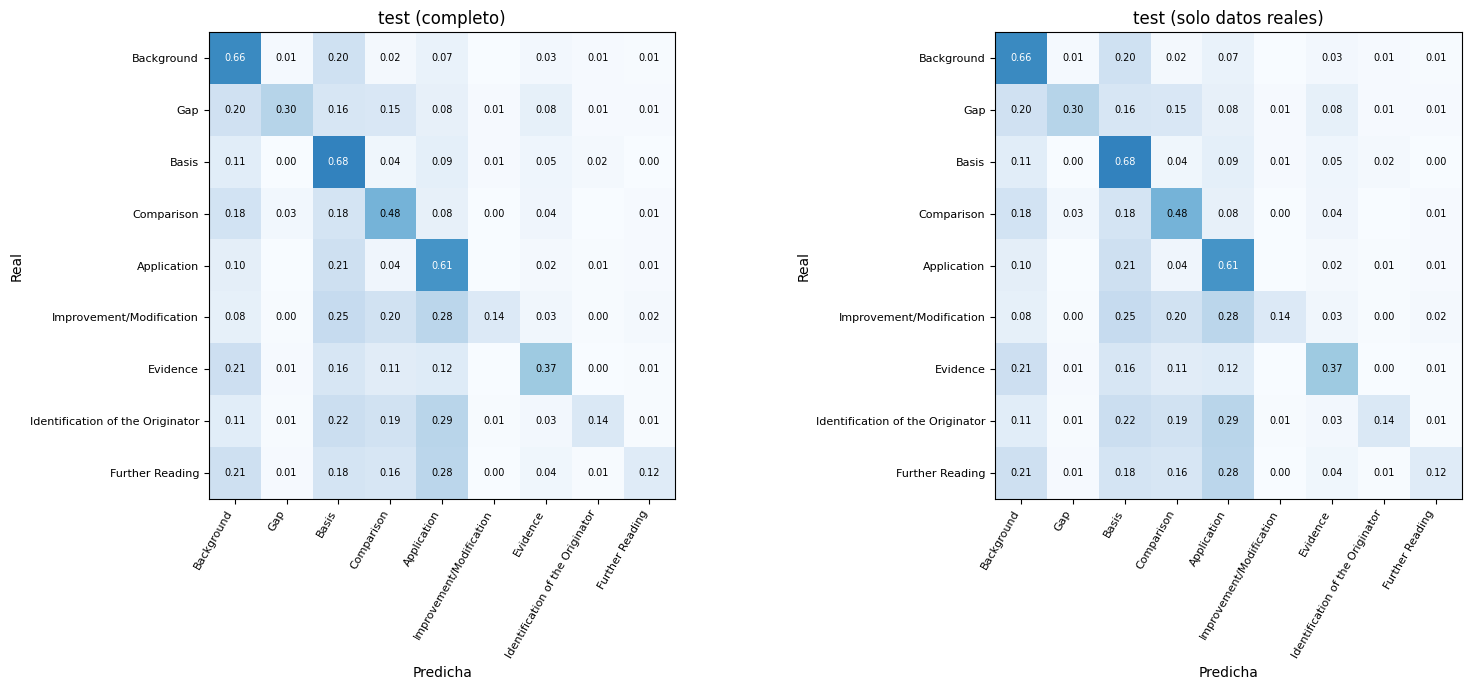

Confusiones más frecuentes (real -> predicha):


citas
real                             predicha          
Further Reading                  Application    189
                                 Background     139
                                 Basis          118
Evidence                         Background     114
Further Reading                  Comparison     107
Background                       Basis          103
Identification of the Originator Application     96
Evidence                         Basis           84
Identification of the Originator Basis           74
Improvement/Modification         Application     71

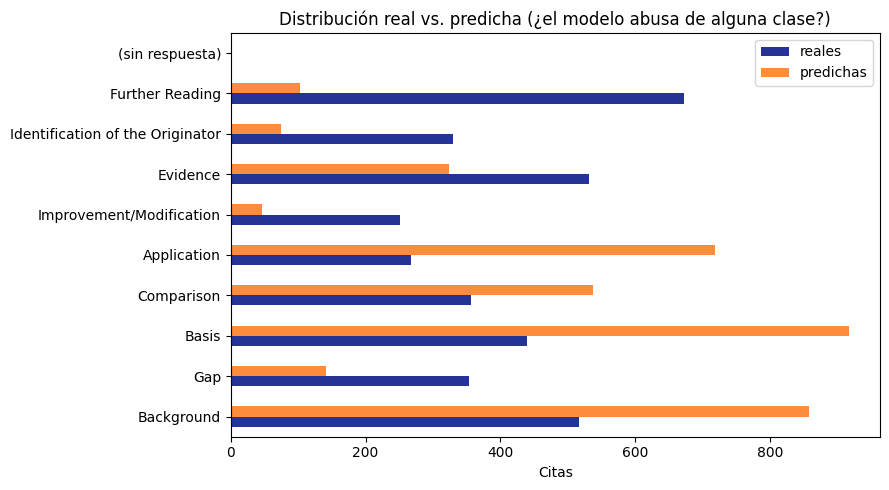

In [11]:
main_sp = "test" if "test" in frames else EVAL_SPLITS[-1]
dfm = frames[main_sp]
cols = LABELS

rep = classification_report(dfm["real"], dfm["predicha"], labels=cols, target_names=cols, output_dict=True, zero_division=0)
print(f"Reporte por clase en {main_sp} (completo):")
display(pd.DataFrame(rep).T.round(3))

def plot_cm(df, title, ax):
    cm = confusion_matrix(df["real"], df["predicha"], labels=cols)
    cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
    ax.set_xticklabels(cols, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(cols, fontsize=8)
    for i in range(len(cols)):
        for j in range(len(cols)):
            if cm[i, j]:
                ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_title(title); ax.set_xlabel("Predicha"); ax.set_ylabel("Real")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
plot_cm(dfm, f"{main_sp} (completo)", axes[0])
real_m = dfm[dfm["origin"] != "synthetic"]
plot_cm(real_m, f"{main_sp} (solo datos reales)", axes[1])
plt.tight_layout(); plt.show()

errs = dfm[dfm["real"] != dfm["predicha"]].groupby(["real", "predicha"]).size().sort_values(ascending=False).head(10)
print("Confusiones más frecuentes (real -> predicha):")
display(errs.rename("citas").to_frame())

comp = pd.DataFrame({"reales": dfm["real"].value_counts(), "predichas": dfm["predicha"].value_counts()}).reindex(cols + [NONE]).fillna(0).astype(int)
ax = comp.plot.barh(figsize=(9, 5), color=["#253494", "#fd8d3c"])
ax.set_title("Distribución real vs. predicha (¿el modelo abusa de alguna clase?)"); ax.set_xlabel("Citas")
plt.tight_layout(); plt.show()

## 8. Guardar resultados

In [12]:
resumen_eval.round(4).to_csv(os.path.join(OUTPUT_DIR, "metricas_evaluacion.csv"))
for sp, df in frames.items():
    df.to_csv(os.path.join(OUTPUT_DIR, f"predicciones_{sp}.csv"), index=False)

config = {"model": MODEL, "entrada": "contexto + título + resumen del documento citado (sin chunks)",
          "temperature": TEMPERATURE, "num_ctx": NUM_CTX, "max_tokens": MAX_TOKENS, "seed": SEED,
          "few_shot_per_class": FEW_SHOT_PER_CLASS, "only_real": ONLY_REAL, "limit_per_class": LIMIT_PER_CLASS,
          "evaluadas": {sp: len(df) for sp, df in frames.items()}}
with open(os.path.join(OUTPUT_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print("Guardado en", OUTPUT_DIR)
print(sorted(os.listdir(OUTPUT_DIR)))

Guardado en /content/drive/MyDrive/Colab Notebooks/proyecto/models/ollama_gemma3_12b
['config.json', 'metricas_evaluacion.csv', 'predicciones_test.csv', 'predicciones_val.csv', 'respuestas_test.jsonl', 'respuestas_val.jsonl']
